# Animal Farming Germany: data quality report

This notebook audits the database built by the pipeline in `scripts/`. It
answers four questions:

1. **Coverage**: how many companies did each source deliver, and how complete are their contact details?
2. **Validity**: are postcodes, cities, emails and websites well-formed?
3. **Classification**: how many machinery makers and livestock farms turned out to be relevant?
4. **Resolution**: how many real companies remain after merging duplicates across sources?

The notebook opens the database **read-only**, so it never changes any data.
Run `python scripts/run_pipeline.py` first to build the database.

In [1]:
import os
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Works when started from the project root or from notebooks/.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB_PATH = Path(os.environ.get("AFG_DB_PATH", ROOT / "data/database/animal_farming_germany_v2.db"))

# mode=ro: SQLite refuses every write, so the audit cannot alter the data.
conn = sqlite3.connect(f"file:{DB_PATH.as_posix()}?mode=ro", uri=True)


def sql(query):
    return pd.read_sql_query(query, conn)


# One quiet chart style for the whole report.
BLUE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})


def barh(series, title, xlabel):
    """Horizontal bar chart, largest bar on top, value at each bar end."""
    series = series.sort_values()
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(series) + 1))
    ax.barh(series.index.astype(str), series.values, color=BLUE, height=0.7)
    ax.grid(axis="y", visible=False)
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold")
    ax.set_xlabel(xlabel)

    for y, value in enumerate(series.values):
        ax.text(value, y, f" {value:,}", va="center", color=MUTED, fontsize=9)

    plt.tight_layout()
    plt.show()

## 1. Coverage: records per source

Every pipeline step stores the companies it finds in the staging table
`discovery_candidates`, one row per company and source. The `_pct` columns show
how complete each source's contact data is. A low share is often a property of
the source (e.g. BfT publishes no addresses) rather than an extraction error.

In [2]:
coverage = sql("""
    SELECT source_name AS source,
           COUNT(*)    AS records,
           ROUND(100.0 * COUNT(NULLIF(TRIM(city), ''))    / COUNT(*)) AS city_pct,
           ROUND(100.0 * COUNT(NULLIF(TRIM(website), '')) / COUNT(*)) AS website_pct,
           ROUND(100.0 * COUNT(NULLIF(TRIM(email), ''))   / COUNT(*)) AS email_pct,
           ROUND(100.0 * COUNT(NULLIF(TRIM(phone), ''))   / COUNT(*)) AS phone_pct
    FROM discovery_candidates
    GROUP BY source_name
    ORDER BY records DESC
""").set_index("source")

total = coverage["records"].sum()
print(f"{total:,} records from {len(coverage)} sources")
coverage

1,168 records from 14 sources


,records,city_pct,website_pct,email_pct,phone_pct
source,,,,,
DVT Member Directory,211,100.0,93.0,97.0,92.0
BRS Member Directory,181,100.0,86.0,95.0,0.0
Export-Union Dairy Member Directory,175,100.0,40.0,37.0,39.0
MIV Milchindustrie-Verband Member Directory,170,100.0,98.0,94.0,98.0
VDMA Landtechnik Member Directory,155,100.0,96.0,100.0,100.0
BVWS Meat Processing Member Directory,101,100.0,97.0,95.0,100.0
VDF Meat Industry Member Directory - Slaughtering,65,100.0,94.0,98.0,100.0
BfT Member Directory,24,0.0,100.0,0.0,0.0
ASR Cattle Breeding Member Directory,23,100.0,100.0,100.0,0.0


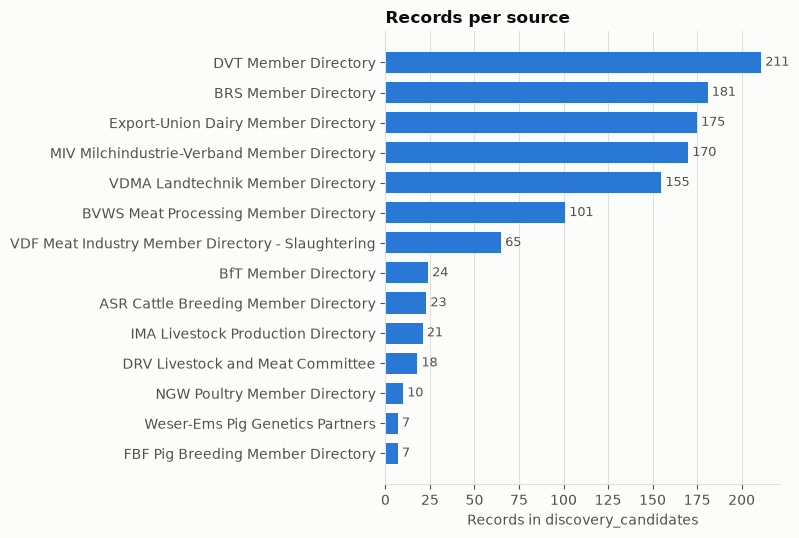

In [3]:
barh(coverage["records"], "Records per source", "Records in discovery_candidates")

## 2. Validity checks

Each check counts values that are present but **malformed**. Empty values are
coverage gaps, not errors, so they are left out here.

In [4]:
validity = sql("""
    SELECT
      SUM(TRIM(postal_code) != '' AND postal_code NOT GLOB '[0-9][0-9][0-9][0-9][0-9]')
          AS postcode_not_5_digits,
      -- 'Tel:' / 'Tel.' rather than 'Tel', which would also flag
      -- towns such as Wolfenbüttel or Mittelfranken.
      SUM(city GLOB '*[0-9]*' OR city LIKE '%Tel:%' OR city LIKE '%Tel.%'
          OR city LIKE '%Telefon%' OR city LIKE '%www.%' OR city LIKE '%@%')
          AS city_contains_contact_text,
      SUM(TRIM(email) != '' AND email NOT LIKE '%_@_%._%')
          AS email_malformed,
      SUM(TRIM(website) != '' AND website NOT LIKE 'http%')
          AS website_without_scheme,
      SUM(company LIKE '%' || char(10) || '%')
          AS company_name_with_line_break
    FROM discovery_candidates
""").T.rename(columns={0: "rows"})

validity

,rows
postcode_not_5_digits,3
city_contains_contact_text,0
email_malformed,4
website_without_scheme,2
company_name_with_line_break,11


The flagged rows, with the source they came from:

In [5]:
sql("""
    SELECT 'postcode' AS problem, source_name, company, postal_code AS value
    FROM discovery_candidates
    WHERE TRIM(postal_code) != '' AND postal_code NOT GLOB '[0-9][0-9][0-9][0-9][0-9]'
    UNION ALL
    SELECT 'email', source_name, company, email FROM discovery_candidates
    WHERE TRIM(email) != '' AND email NOT LIKE '%_@_%._%'
    UNION ALL
    SELECT DISTINCT 'website', source_name, company, website FROM discovery_candidates
    WHERE TRIM(website) != '' AND website NOT LIKE 'http%'
""")

,problem,source_name,company,value
0,postcode,BRS Member Directory,IMV Technologies,F - 61300
1,postcode,BRS Member Directory,"Phileo by Lesaffre Phileo, a division of S.I.L...",F 59703
2,postcode,BRS Member Directory,SUISAG AG für Dienstleistungen in der Schweine...,6204
3,email,DVT Member Directory,AGRAVIS Futtermittel GmbH,www.agravis.de
4,email,DVT Member Directory,Wilhelm Ströh jun. GmbH & Co. KG,info@stroeh-hobbersdorf
5,email,VDMA Landtechnik Member Directory,ZF Friedrichshafen AG,null
6,email,VDF Meat Industry Member Directory - Slaughtering,VION Crailsheim GmbH,https://www.vionfoodgroup.com/de
7,website,MIV Milchindustrie-Verband Member Directory,Milchwerke Oberfranken West eG,hhttp://www.milchwerke-oberfranken.com


Company names with a line break come from the MIV directory, which lists
individual plants as *"Company / Site"*. They are stored exactly as published,
because the name is part of the staging table's unique key.

In [6]:
sql("""
    SELECT company, city FROM discovery_candidates
    WHERE company LIKE '%' || char(10) || '%'
    ORDER BY company
""").replace("\n", " / ", regex=True)

,company,city
0,Arla Foods Deutschland GmbH / Niederlassung Pr...,Pronsfeld
1,Arla Foods Deutschland GmbH / Niederlassung Upahl,Upahl
2,Bayernland eG / Hauptverwaltung,Nürnberg
3,CONDETTA GmbH & Co. KG / Storck Industrie-Service,Halle (Westfalen)
4,DMK Deutsches Milchkontor GmbH / Standort Waren,Waren (Müritz)
5,Hofmeister Käsewerk GmbH & Co. KG / Werk Pfeff...,Pfeffenhausen
6,MEGGLE Cheese Altusried GmbH / Produktion,Altusried
7,Meierei Barmstedt eG / Werk Barmstedt,Barmstedt
8,Meierei Barmstedt eG / Werk Neumünster,Neumünster
9,Molkerei Hainichen-Freiberg GmbH & Co. KG / Be...,"Freiberg, Sachsen"


## 3. Classification

Two sources list companies whose relevance to livestock farming is unknown at
first. The pipeline checks their websites for keyword evidence.

### 3a. Machinery makers (VDMA, steps 16 and 17)

Step 16 reads each homepage. Step 17 takes a second, deeper look at the
companies whose homepage loaded but gave no evidence. The final label is the
step 16 result, replaced by the step 17 result wherever step 17 ran.

In [7]:
equipment = sql("""
    SELECT r.relevance AS first_pass,
           COALESCE(e.classification, r.relevance) AS final_label
    FROM company_relevance r
    LEFT JOIN company_activity_enrichment e USING (discovery_id)
""")

funnel = pd.DataFrame({
    "after step 16": equipment["first_pass"].value_counts(),
    "final": equipment["final_label"].value_counts(),
}).reindex(["direct", "indirect", "crop_focused", "unknown"]).fillna(0).astype(int)

print("Machinery makers checked:", len(equipment))
funnel

Machinery makers checked: 155


,after step 16,final
direct,13,15
indirect,4,5
crop_focused,5,7
unknown,133,128


Why a homepage could not be classified in step 16:

In [8]:
sql("""
    SELECT classification_status AS status, COUNT(*) AS companies
    FROM company_relevance GROUP BY 1 ORDER BY 2 DESC
""")

,status,companies
0,success,124
1,robots_unavailable_or_disallowed,15
2,request_failed,10
3,missing_website,6


### 3b. Livestock producers (IMA, step 19)

Corporate farms from the IMA directory, labelled by the animals their website
mentions. Farms whose website could not be read keep the placeholder sector.

In [9]:
sql("""
    SELECT sector, COUNT(*) AS farms
    FROM discovery_candidates
    WHERE source_name = 'IMA Livestock Production Directory'
    GROUP BY sector ORDER BY farms DESC
""")

,sector,farms
0,Livestock Farming - Relevance Unverified,18
1,Pig Production,1
2,Mixed Livestock Production,1
3,Dairy Farming,1


## 4. Entity resolution (step 20)

The same company is often listed by several associations. Step 20 merges
staging rows on a normalised company name, so each company appears once.

In [10]:
resolved = sql("""
    SELECT c.company_id, c.company_name,
           COUNT(DISTINCT s.source_name) AS sources
    FROM resolved_companies c
    JOIN resolved_company_sources s USING (company_id)
    GROUP BY c.company_id
""")

print(f"Staging rows:       {total:,}")
print(f"Resolved companies: {len(resolved):,}")
print(f"Merged away:        {total - len(resolved):,} rows ({1 - len(resolved) / total:.0%})")

listed_by = resolved["sources"].value_counts().sort_index()
listed_by.index = [f"{n} source" + ("s" if n > 1 else "") for n in listed_by.index]
listed_by.rename("companies").to_frame()

Staging rows:       1,168
Resolved companies: 950
Merged away:        218 rows (19%)


,companies
1 source,827
2 sources,117
3 sources,6


Companies confirmed by **several independent sources** are the most reliable entries:

In [11]:
sql("""
    SELECT c.company_name,
           COUNT(DISTINCT s.source_name)        AS sources,
           GROUP_CONCAT(DISTINCT s.source_name) AS listed_by
    FROM resolved_companies c
    JOIN resolved_company_sources s USING (company_id)
    GROUP BY c.company_id
    HAVING sources > 1
    ORDER BY sources DESC, c.company_name
    LIMIT 15
""")

,company_name,sources,listed_by
0,BHZP GmbH,3,"BRS Member Directory,FBF Pig Breeding Member D..."
1,Deutsche Vilomix Tierernährung GmbH,3,"DVT Member Directory,BRS Member Directory,NGW ..."
2,Elanco Deutschland GmbH,3,"DVT Member Directory,BfT Member Directory,BRS ..."
3,MEGGLE GmbH & Co. KG,3,"DVT Member Directory,MIV Milchindustrie-Verban..."
4,Privatmolkerei Bauer GmbH & Co KG,3,"BRS Member Directory,MIV Milchindustrie-Verban..."
5,Zoetis Deutschland GmbH,3,"DVT Member Directory,BfT Member Directory,BRS ..."
6,AGRAVIS Futtermittel GmbH,2,"DVT Member Directory,BRS Member Directory"
7,ASL GmbH & Co. KG,2,"DVT Member Directory,BRS Member Directory"
8,Agri V Raiffeisen eG,2,"DVT Member Directory,DRV Livestock and Meat Co..."
9,Alpavit GmbH & Co. KG,2,"MIV Milchindustrie-Verband Member Directory,Ex..."


## 5. Where are the companies?

The first digit of a German postcode is its *postcode zone*, a rough region
(e.g. 4 = north-west including Münsterland, 7 = Baden-Württemberg, 8 = southern
Bavaria). Each company/postcode pair is counted once.

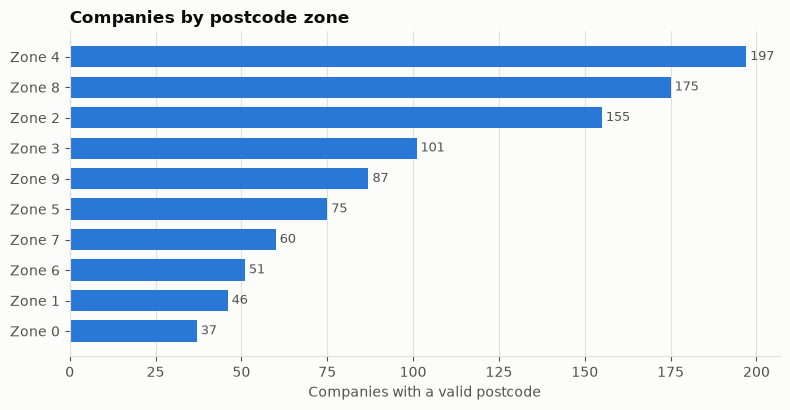

In [12]:
zones = sql("""
    SELECT SUBSTR(postal_code, 1, 1) AS zone,
           COUNT(DISTINCT company || postal_code) AS companies
    FROM discovery_candidates
    WHERE postal_code GLOB '[0-9][0-9][0-9][0-9][0-9]'
    GROUP BY zone
""").set_index("zone")["companies"]
zones.index = "Zone " + zones.index

barh(zones, "Companies by postcode zone", "Companies with a valid postcode")

## 6. Findings

**Coverage.** 14 public directories delivered 1,168 company records. Every
source that publishes addresses has a city for at least 86% of its records.
Contact data is weakest for Export-Union dairy exporters (about 40% have a
website), even after step 18 filled gaps from their profile pages.

**Validity.** Out of 1,168 records, 9 values are malformed, and all of them
were already wrong on the source websites:

- 3 BRS members are not German (French and Swiss postcodes). BRS step 05 keeps
  every member, so a country filter like the one in steps 02 and 04 would fix this.
- 4 emails are not addresses: a website in the email field, the text "null",
  or a missing domain ending.
- 1 MIV company publishes its website as "hhttp://..." (stored on 2 rows).

These are left as published. A cleaning step can fix them without touching the
extraction code.

**Classification.** Website keywords confirmed 20 of 155 machinery makers as
livestock-relevant (15 direct, 5 indirect) and 7 as crop-focused. 128 remain
unknown: 31 websites could not be read at all (robots.txt, errors, no website),
and many others describe products without the keywords. Keyword matching is
cheap and transparent but has low recall; the unknown group needs a manual check
or a stronger text classifier.

**Resolution.** Merging on normalised names reduced 1,168 records to 950 distinct
companies. 123 companies are confirmed by two or more independent sources,
which makes them the most reliable part of the dataset.

**Geography.** Postcode zone 4 (north-west Germany, including the Weser-Ems and
Münsterland livestock regions) has the most companies, followed by zone 8
(southern Bavaria, a major dairy region).

In [13]:
conn.close()